Rechnet auf: mps
Verwendetes Bild: bild.jpg   Größe: (1546, 1213)


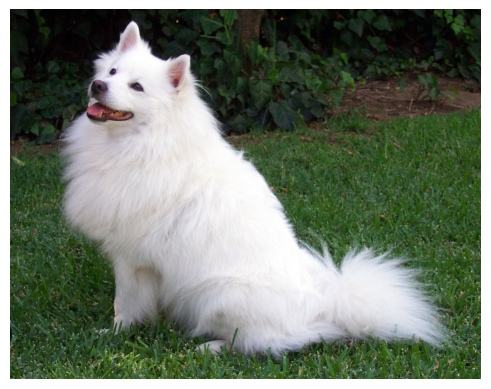


Top 5 von VGG16:
   258  Samoyed                      0.840
   259  Pomeranian                   0.033
   248  Eskimo dog                   0.017
   270  white wolf                   0.016
   257  Great Pyrenees               0.012

Erklärte Klasse: Samoyed  (P = 0.840)

=== Beitrag zur WAHRSCHEINLICHKEIT ===
[[ 0.383 -0.023 -0.008  0.02 ]
 [ 0.151  0.046  0.012 -0.001]
 [ 0.113 -0.004  0.024  0.061]
 [ 0.027  0.037 -0.042  0.08 ]]
Basis 0.0006 + Summe 0.8755 = 0.8760   (ganzes Bild: 0.8760)

=== Beitrag zur UNSICHERHEIT ===
[[-1.8382e+00 -1.8000e-03  4.7200e-02 -1.6150e-01]
 [-7.7800e-01 -3.3000e-01 -4.2300e-02  3.3300e-02]
 [-6.1140e-01 -1.5430e-01 -2.5470e-01 -3.4190e-01]
 [-1.1640e-01 -2.6160e-01  2.0900e-01 -4.7580e-01]]
Basis 5.86909 + Summe -5.07860 = 0.79049   (ganzes Bild: 0.79049)


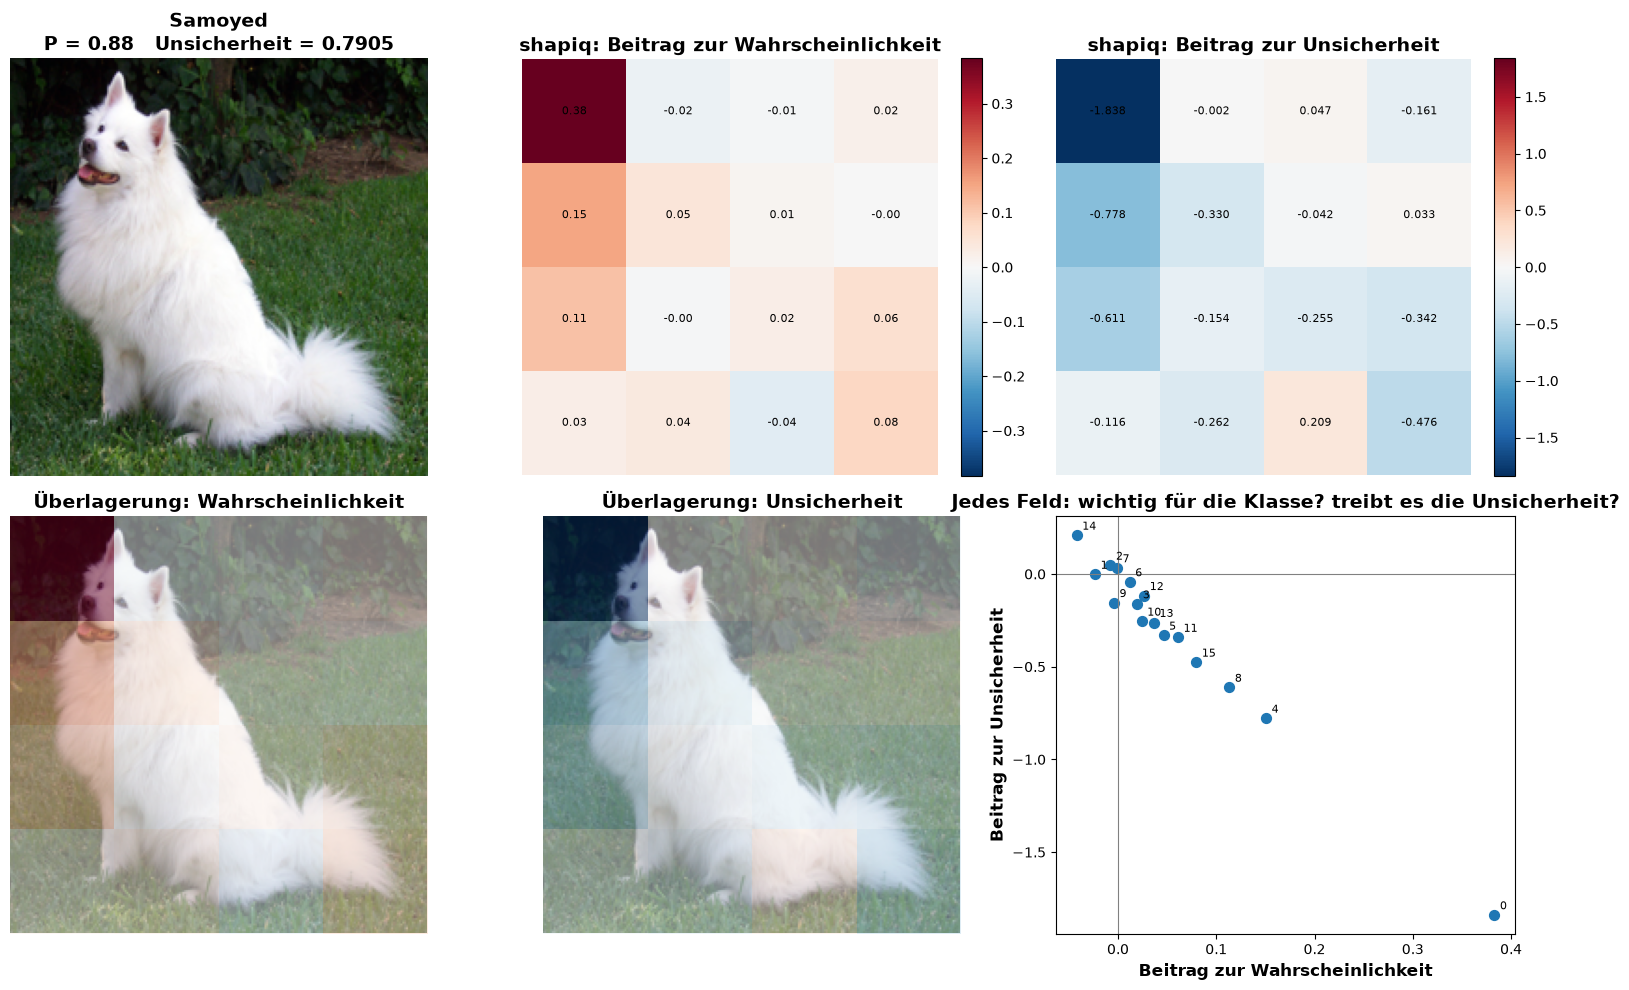


Wichtigstes Feld für die Klasse:           Feld 0  (+0.3831)
Feld mit größtem Beitrag zur Unsicherheit: Feld 14  (+0.20899)
Korrelation der beiden Beitragslisten:     -0.992
GANZES BILD
  total     = 1.4552
  aleatoric = 1.2812
  epistemic = 0.1739
  Kontrolle: aleatoric + epistemic = 1.4552

total (Änderung, wenn das Feld fehlt):
[[ 1.1384 -0.8071 -0.6575 -0.5158]
 [ 0.7196 -0.9939 -0.2571 -0.5655]
 [-0.2829 -0.5064 -0.6496 -0.1569]
 [-0.2809 -0.7043 -0.886  -0.1963]]

aleatoric (Änderung, wenn das Feld fehlt):
[[ 0.7541 -0.7476 -0.5709 -0.4864]
 [ 0.611  -0.8555 -0.213  -0.4767]
 [-0.2586 -0.5025 -0.5563 -0.135 ]
 [-0.2746 -0.5883 -0.7703 -0.1943]]

epistemic (Änderung, wenn das Feld fehlt):
[[ 0.3844 -0.0595 -0.0866 -0.0295]
 [ 0.1086 -0.1384 -0.0441 -0.0888]
 [-0.0243 -0.004  -0.0933 -0.0219]
 [-0.0063 -0.1159 -0.1156 -0.002 ]]


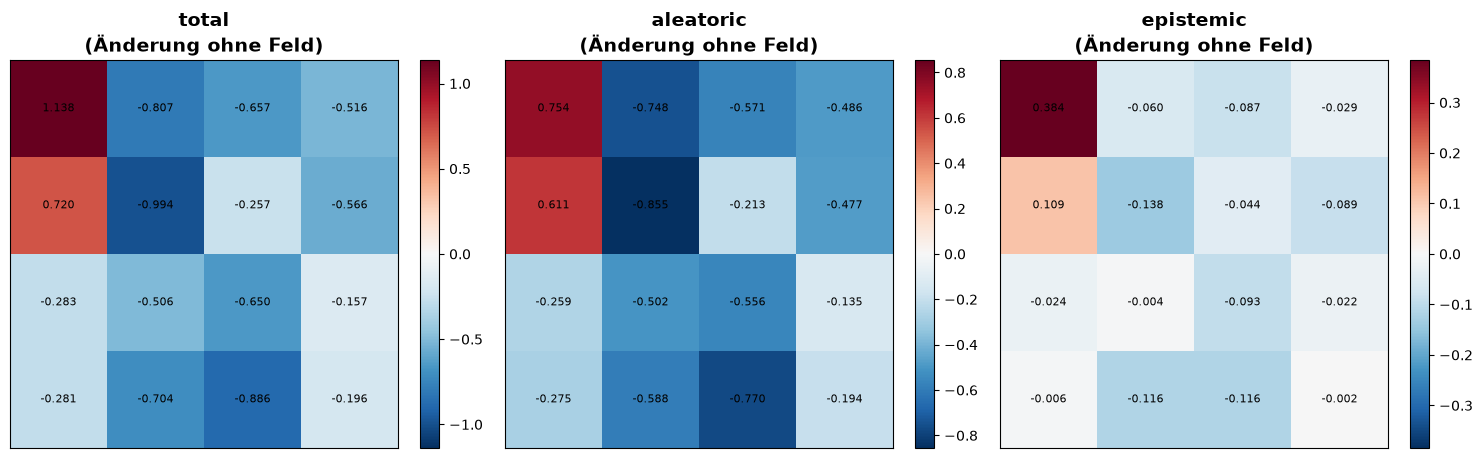

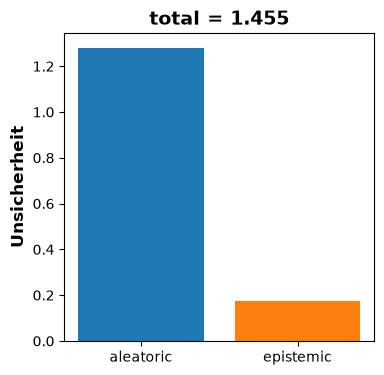

In [4]:
# ============================================================
# 0. EINSTELLUNGEN
# ============================================================
BILD_PFAD   = None     # z.B. "katze.jpg". None = Auswahl aus einer Liste der Bilder im Ordner
ZIEL_NAME   = None     # z.B. "tabby". None = wahrscheinlichste Klasse
N           = 4       # Raster N x N (3 = 9 Felder, 4 = 16 Felder)
NUM_SAMPLES = 5       # Dropout-Durchläufe pro Bildvariante
BUDGET      = 1024     # Kombinationen bei der Näherung (nur bei mehr als 10 Feldern)

# ============================================================
# 1. Imports und Gerät (GPU, wenn vorhanden)
# ============================================================
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"      # nicht unterstützte Operationen laufen dann auf der CPU
                                                      # (muss VOR dem Import von torch stehen)
import glob, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision.models import vgg16, VGG16_Weights
import shapiq
from shapiq.approximator import KernelSHAP
from probly.method import dropout
from probly.representer import representer
from probly.quantification import quantify

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Rechnet auf:", device)

# ============================================================
# 2. Bild auswählen
# ============================================================

import os
from PIL import Image

BILD_PFAD = "bild.jpg"      # <-- hier den Pfad eintragen, z.B. "katze.jpg" oder "/Users/tristanfuchs/Bilder/hund.png"

BILD_PFAD = os.path.expanduser(BILD_PFAD)               # "~" wird zum Home-Ordner
if not os.path.exists(BILD_PFAD):
    raise FileNotFoundError(f"Bild nicht gefunden: {BILD_PFAD}\nAktueller Ordner: {os.getcwd()}")

bild = Image.open(BILD_PFAD).convert("RGB")
print("Verwendetes Bild:", BILD_PFAD, "  Größe:", bild.size)
plt.imshow(bild); plt.axis("off"); plt.show()

# ============================================================
# 3. VGG16 auf die GPU legen, Bild vorbereiten, Zielklasse bestimmen
# ============================================================
gewichte = VGG16_Weights.IMAGENET1K_V1
vgg = vgg16(weights=gewichte).eval().to(device)            # Netz auf die GPU
klassen = gewichte.meta["categories"]

x = gewichte.transforms()(bild).unsqueeze(0).to(device)    # Bild auf die GPU
with torch.no_grad():
    wahrsch = torch.softmax(vgg(x), dim=1)[0].cpu()        # fürs Anzeigen zurück auf die CPU

top5 = torch.topk(wahrsch, 5)
print("\nTop 5 von VGG16:")
for p, i in zip(top5.values, top5.indices):
    print(f"  {int(i):4d}  {klassen[int(i)]:28s} {p.item():.3f}")

if ZIEL_NAME is None:
    ziel = int(wahrsch.argmax())
else:
    treffer = [i for i, k in enumerate(klassen) if ZIEL_NAME.lower() in k.lower()]
    if not treffer:
        raise ValueError(f"Keine Klasse mit '{ZIEL_NAME}' gefunden")
    ziel = treffer[0]
print(f"\nErklärte Klasse: {klassen[ziel]}  (P = {wahrsch[ziel]:.3f})")

# ============================================================
# 4. Bild in N x N Felder teilen (Masken liegen auf der GPU)
# ============================================================
n_spieler = N * N
grenzen = np.linspace(0, 224, N + 1).astype(int)
feld_masken = []
for r in range(N):
    for c in range(N):
        m = torch.zeros(224, 224)
        m[grenzen[r]:grenzen[r + 1], grenzen[c]:grenzen[c + 1]] = 1
        feld_masken.append(m)
feld_masken = torch.stack(feld_masken).to(device)

# ============================================================
# 5. probly: Dropout-Modell (nach dem Verschieben von vgg auf die GPU bauen)
# ============================================================
mc  = dropout(vgg, p=0.2, predictor_type="logit_classifier")
rep = representer(mc, num_samples=NUM_SAMPLES)

def bewerte(koalitionen, batch=16):
    k = torch.tensor(koalitionen, dtype=torch.float32, device=device)
    ps, us = [], []
    for start in range(0, len(k), batch):
        teil = k[start:start + batch]
        maske = (teil[:, :, None, None] * feld_masken[None]).sum(1)
        bilder = x * maske[:, None]
        with torch.no_grad():
            sample = rep.represent(bilder)
            ps.append(sample.sample_mean().probabilities[:, ziel].detach().cpu().numpy())
            us.append(quantify(sample).total.detach().cpu().numpy())
    return np.concatenate(ps).astype(float), np.concatenate(us).astype(float)

cache = {}
def hole(koal):
    keys = [tuple(bool(b) for b in z) for z in koal]
    fehlend = [k for k in dict.fromkeys(keys) if k not in cache]
    if fehlend:
        p, u = bewerte(np.array(fehlend))
        for k, pv, uv in zip(fehlend, p, u):
            cache[k] = (pv, uv)
    return keys

def spiel_p(koal): return np.array([cache[k][0] for k in hole(koal)], dtype=float)
def spiel_u(koal): return np.array([cache[k][1] for k in hole(koal)], dtype=float)

# ============================================================
# 6. shapiq
# ============================================================
def shapley(spiel):
    if n_spieler <= 10:
        sv = shapiq.ExactComputer(game=spiel, n_players=n_spieler)(index="SV", order=1)
    else:
        sv = KernelSHAP(n=n_spieler, random_state=0).approximate(budget=BUDGET, game=spiel)
    werte = np.array([sv.dict_values.get((i,), 0.0) for i in range(n_spieler)])
    return werte, sv.baseline_value

werte_p, basis_p = shapley(spiel_p)
werte_u, basis_u = shapley(spiel_u)

voll = tuple([True] * n_spieler)
spiel_p(np.array([voll]))
P_voll, U_voll = cache[voll]

print("\n=== Beitrag zur WAHRSCHEINLICHKEIT ===")
print(np.round(werte_p.reshape(N, N), 3))
print(f"Basis {basis_p:.4f} + Summe {werte_p.sum():.4f} = {basis_p + werte_p.sum():.4f}   (ganzes Bild: {P_voll:.4f})")
print("\n=== Beitrag zur UNSICHERHEIT ===")
print(np.round(werte_u.reshape(N, N), 4))
print(f"Basis {basis_u:.5f} + Summe {werte_u.sum():.5f} = {basis_u + werte_u.sum():.5f}   (ganzes Bild: {U_voll:.5f})")

# ============================================================
# 7. Grafik
# ============================================================
karte_p, karte_u = werte_p.reshape(N, N), werte_u.reshape(N, N)
bild_224 = bild.resize((224, 224))
schrift = 8 if N > 3 else 10

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes[0, 0].imshow(bild_224); axes[0, 0].axis("off")
axes[0, 0].set_title(f"{klassen[ziel]}\nP = {P_voll:.2f}   Unsicherheit = {U_voll:.4f}")

for ax, karte, titel, fmt in [(axes[0, 1], karte_p, "shapiq: Beitrag zur Wahrscheinlichkeit", "{:.2f}"),
                              (axes[0, 2], karte_u, "shapiq: Beitrag zur Unsicherheit", "{:.3f}")]:
    g = np.abs(karte).max()
    im = ax.imshow(karte, cmap="RdBu_r", vmin=-g, vmax=g)
    for r in range(N):
        for c in range(N):
            ax.text(c, r, fmt.format(karte[r, c]), ha="center", va="center", fontsize=schrift)
    ax.set_title(titel); ax.axis("off"); fig.colorbar(im, ax=ax, fraction=0.046)

for ax, karte, titel in [(axes[1, 0], karte_p, "Überlagerung: Wahrscheinlichkeit"),
                         (axes[1, 1], karte_u, "Überlagerung: Unsicherheit")]:
    g = np.abs(karte).max()
    ax.imshow(bild_224)
    ax.imshow(karte, cmap="RdBu_r", vmin=-g, vmax=g, alpha=0.5, extent=(0, 224, 224, 0), interpolation="nearest")
    ax.set_title(titel); ax.axis("off")

ax = axes[1, 2]
ax.scatter(werte_p, werte_u, s=50)
for i in range(n_spieler):
    ax.annotate(str(i), (werte_p[i], werte_u[i]), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Beitrag zur Wahrscheinlichkeit"); ax.set_ylabel("Beitrag zur Unsicherheit")
ax.set_title("Jedes Feld: wichtig für die Klasse? treibt es die Unsicherheit?")
plt.tight_layout(); plt.show()

print(f"\nWichtigstes Feld für die Klasse:           Feld {int(np.argmax(werte_p))}  ({werte_p.max():+.4f})")
print(f"Feld mit größtem Beitrag zur Unsicherheit: Feld {int(np.argmax(werte_u))}  ({werte_u.max():+.5f})")
print(f"Korrelation der beiden Beitragslisten:     {np.corrcoef(werte_p, werte_u)[0, 1]:+.3f}")





# ===== Zusatz: total, aleatoric, epistemic je Feld =====
import numpy as np
import torch
import matplotlib.pyplot as plt
from probly.quantification import quantify

H = x.shape[-1]
schritt = H // N

# 1) Varianten bauen: Variante 0 = ganzes Bild, danach jeweils ein Feld auf 0 gesetzt
varianten = [x.clone()]
for i in range(N):
    for j in range(N):
        v = x.clone()
        v[:, :, i*schritt:(i+1)*schritt, j*schritt:(j+1)*schritt] = 0
        varianten.append(v)
varianten = torch.cat(varianten).to(device)

# 2) Durch das Netz mit Dropout, jeweils 16 auf einmal
tot, ale, epi = [], [], []
with torch.no_grad():
    for k in range(0, len(varianten), 16):
        q = quantify(rep.represent(varianten[k:k+16]))
        tot.append(q.total.detach().cpu().numpy())
        ale.append(q.aleatoric.detach().cpu().numpy())
        epi.append(q.epistemic.detach().cpu().numpy())
tot, ale, epi = np.concatenate(tot), np.concatenate(ale), np.concatenate(epi)

# 3) Zahlen ausgeben
print("GANZES BILD")
print(f"  total     = {tot[0]:.4f}")
print(f"  aleatoric = {ale[0]:.4f}")
print(f"  epistemic = {epi[0]:.4f}")
print(f"  Kontrolle: aleatoric + epistemic = {ale[0] + epi[0]:.4f}")

# 4) Änderung pro Feld: Wert mit ausgeschaltetem Feld minus Wert beim ganzen Bild
#    positiv = ohne dieses Feld ist es unsicherer (Feld machte es sicherer)
#    negativ = ohne dieses Feld ist es sicherer (Feld trug Unsicherheit bei)
def karte(werte):
    return (werte[1:] - werte[0]).reshape(N, N)

karten = {"total": karte(tot), "aleatoric": karte(ale), "epistemic": karte(epi)}

for name, k in karten.items():
    print(f"\n{name} (Änderung, wenn das Feld fehlt):")
    print(np.round(k, 4))

# 5) Grafik: drei Karten nebeneinander
fig, achsen = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, k) in zip(achsen, karten.items()):
    m = np.abs(k).max() + 1e-12
    bild = ax.imshow(k, cmap="RdBu_r", vmin=-m, vmax=m)
    ax.set_title(f"{name}\n(Änderung ohne Feld)")
    ax.set_xticks([]); ax.set_yticks([])
    for i in range(N):
        for j in range(N):
            ax.text(j, i, f"{k[i, j]:.3f}", ha="center", va="center", fontsize=8)
    plt.colorbar(bild, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# 6) Balken: Aufteilung der Gesamtunsicherheit beim ganzen Bild
plt.figure(figsize=(4, 4))
plt.bar(["aleatoric", "epistemic"], [ale[0], epi[0]], color=["tab:blue", "tab:orange"])
plt.title(f"total = {tot[0]:.3f}")
plt.ylabel("Unsicherheit")
plt.show()

sample_mean() mittelt die 5 Antworten: die Wahrscheinlichkeit. Den Mittelwert der Durchläufe der Zielklasse


quantify misst, wie stark die 5 Antworten auseinanderliegen: die Unsicherheit. Die Streung der Durchläufe, berechent mit quantify 


Aleatoric ist die Unsicherheit, die im Bild selbst steckt. Das Bild ist mehrdeutig oder unscharf, zum Beispiel ähneln sich viele Hunderassen. Jeder einzelne Dropout-Durchlauf ist dann schon unentschieden. Mehr Durchläufe oder ein besseres Netz ändern daran wenig, weil das Bild selbst unklar ist.


Epistemic ist die Unsicherheit des Netzes. Es weiß zu wenig, und die Dropout-Durchläufe widersprechen sich: Durchlauf 1 sagt „Labrador“, Durchlauf 2 sagt „Boxer“. Mehr Wissen oder mehr Trainingsdaten könnten sie verringern.